# BIOL 360 — Molecular Cell Biology
## Powering the Cell: Mitochondria, Chloroplasts, and Energy Conversion

### Computational laboratory notebook

**Central question:**  
How do electron transport, proton gradients, membrane permeability, and ATP synthase interact to control cellular ATP production?

This notebook is the computational companion to the BIOL 360 lab protocol.

### What you will do
You will:

1. Establish normal mitochondrial and chloroplast conditions.
2. **Change model parameters yourself** to simulate biological perturbations.
3. Generate time-course and endpoint-comparison plots.
4. Diagnose unknown perturbations from their energy-conversion signatures.
5. Design and test one experiment of your own.

> **Important:** This is a simplified conceptual model designed to teach biological relationships. Values are in **relative units** and are not intended to reproduce the exact kinetics of a particular species, tissue, respiratory complex, or chloroplast.

### Rule for this notebook
Do **not** use **Runtime → Run all** as a substitute for doing the experiment.

Several experiment cells contain `None`. They will not generate experimental results until **you replace `None` with a biologically meaningful numerical value**.

## How to work in this notebook

For each experiment:

**1. Predict** what will happen before running the model. Record your prediction in the lab protocol.

**2. Edit the parameter** marked `TODO`.

**3. Run the cell.**

**4. Examine both:**
- the numerical output table, and
- the plot.

**5. Explain the biology** in the lab protocol.

### Parameter scale

Unless otherwise noted:

- `1.0` = normal activity
- `0.5` = 50% of normal
- `0.0` = no activity
- values above `1.0` = activity above the normal reference condition

For proton leak, the normal reference value is `0.10`.

## 1. Setup

Run the code cell below **once** before beginning the experiments.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.precision", 3)

# ------------------------------------------------------------
# CONCEPTUAL ENERGY-CONVERSION MODELS
# ------------------------------------------------------------
# These equations intentionally simplify many real biochemical steps.
# Their purpose is to reproduce the qualitative relationships among:
# electron transport, proton pumping, proton leak, ATP synthase, and ATP output.

MITO_CONTROL = {
    "electron_transport_activity": 1.0,
    "proton_leak": 0.10,
    "atp_synthase_activity": 1.0,
}

CHLORO_CONTROL = {
    "light_intensity": 1.0,
    "photosynthetic_et_activity": 1.0,
    "proton_leak": 0.10,
    "atp_synthase_activity": 1.0,
}

RESULTS = {}

def _simulate_mito_raw(electron_transport_activity=1.0,
                       proton_leak=0.10,
                       atp_synthase_activity=1.0,
                       duration=30,
                       dt=0.05):
    """Simplified mitochondrial chemiosmosis model."""
    gradient = 0.05
    rows = []

    for time in np.arange(0, duration + dt, dt):
        # A large proton gradient creates backpressure on electron transport.
        electron_flow = electron_transport_activity / (1 + 0.85 * gradient)

        proton_pumping = 1.35 * electron_flow
        atp_flux = 0.80 * atp_synthase_activity * gradient
        leak_flux = 3.50 * proton_leak * gradient

        rows.append([
            time,
            electron_flow,
            gradient,
            atp_flux,
            electron_flow,
        ])

        d_gradient = proton_pumping - atp_flux - leak_flux
        gradient = max(0.0, gradient + dt * d_gradient)

    return pd.DataFrame(
        rows,
        columns=[
            "time",
            "electron_transport",
            "proton_gradient",
            "atp_production",
            "oxygen_consumption",
        ],
    )

def _simulate_chloro_raw(light_intensity=1.0,
                         photosynthetic_et_activity=1.0,
                         proton_leak=0.10,
                         atp_synthase_activity=1.0,
                         duration=30,
                         dt=0.05):
    """Simplified chloroplast photophosphorylation model."""
    gradient = 0.05
    rows = []

    for time in np.arange(0, duration + dt, dt):
        available_energy = light_intensity * photosynthetic_et_activity
        electron_flow = available_energy / (1 + 0.75 * gradient)

        proton_pumping = 1.35 * electron_flow
        atp_flux = 0.80 * atp_synthase_activity * gradient
        leak_flux = 3.50 * proton_leak * gradient

        rows.append([
            time,
            electron_flow,
            gradient,
            atp_flux,
        ])

        d_gradient = proton_pumping - atp_flux - leak_flux
        gradient = max(0.0, gradient + dt * d_gradient)

    return pd.DataFrame(
        rows,
        columns=[
            "time",
            "electron_transport",
            "proton_gradient",
            "atp_production",
        ],
    )

# Establish reference end-point values for normalization.
_MITO_REF_RAW = _simulate_mito_raw().iloc[-1]
_CHLORO_REF_RAW = _simulate_chloro_raw().iloc[-1]

def simulate_mito(electron_transport_activity=1.0,
                  proton_leak=0.10,
                  atp_synthase_activity=1.0):
    raw = _simulate_mito_raw(
        electron_transport_activity,
        proton_leak,
        atp_synthase_activity,
    )
    normalized = raw.copy()
    for metric in [
        "electron_transport",
        "proton_gradient",
        "atp_production",
        "oxygen_consumption",
    ]:
        normalized[metric] = raw[metric] / _MITO_REF_RAW[metric]
    return normalized

def simulate_chloro(light_intensity=1.0,
                    photosynthetic_et_activity=1.0,
                    proton_leak=0.10,
                    atp_synthase_activity=1.0):
    raw = _simulate_chloro_raw(
        light_intensity,
        photosynthetic_et_activity,
        proton_leak,
        atp_synthase_activity,
    )
    normalized = raw.copy()
    for metric in [
        "electron_transport",
        "proton_gradient",
        "atp_production",
    ]:
        normalized[metric] = raw[metric] / _CHLORO_REF_RAW[metric]
    return normalized

def endpoint(trace):
    """Return the final relative values from a simulation."""
    return trace.drop(columns="time").iloc[-1].round(3)

def plot_time_course(trace, title, metrics):
    """Plot selected relative metrics through simulated time."""
    fig, ax = plt.subplots(figsize=(8, 4.5))
    for metric in metrics:
        ax.plot(trace["time"], trace[metric], label=metric.replace("_", " ").title())
    ax.axhline(1.0, linestyle="--", linewidth=1, label="Normal reference")
    ax.set_title(title)
    ax.set_xlabel("Simulated time")
    ax.set_ylabel("Relative value")
    ax.legend()
    ax.grid(alpha=0.2)
    plt.show()

def plot_endpoint_comparison(control_endpoint, experimental_endpoint, title):
    """Grouped endpoint comparison."""
    comparison = pd.DataFrame({
        "Control": control_endpoint,
        "Experimental": experimental_endpoint,
    })
    ax = comparison.plot(kind="bar", figsize=(8, 4.5))
    ax.set_title(title)
    ax.set_xlabel("Measurement")
    ax.set_ylabel("Relative value")
    ax.axhline(1.0, linestyle="--", linewidth=1)
    ax.tick_params(axis="x", rotation=25)
    plt.tight_layout()
    plt.show()

def require_parameter_change(value, label, control_value, low=0.0, high=3.0):
    """Guardrail: experiment cells do nothing until the student edits the parameter."""
    if value is None:
        print(f"STOP: Replace None for '{label}' with a numerical value, then run this cell again.")
        return False

    if not isinstance(value, (int, float, np.integer, np.floating)):
        raise TypeError(f"{label} must be a number.")

    if not low <= float(value) <= high:
        raise ValueError(f"{label} must be between {low} and {high} for this lab.")

    if np.isclose(float(value), float(control_value)):
        raise ValueError(
            f"{label} is still at its control value ({control_value}). "
            "Change it before running the experiment."
        )

    return True

def require_plot_metrics(metrics, valid_metrics):
    if metrics is None:
        print("STOP: Replace None with a Python list containing at least two metric names.")
        return False

    if not isinstance(metrics, list) or len(metrics) < 2:
        raise ValueError("Choose at least two metrics in a Python list.")

    invalid = [m for m in metrics if m not in valid_metrics]
    if invalid:
        raise ValueError(f"Invalid metric(s): {invalid}. Valid choices: {valid_metrics}")

    return True

print("Setup complete.")
print("All reported outputs are normalized to the normal control condition = 1.0.")

Setup complete.
All reported outputs are normalized to the normal control condition = 1.0.


## 2. Mitochondrial control

This establishes the normal mitochondrial reference condition:

- Electron transport activity = `1.0`
- Proton leak = `0.10`
- ATP synthase activity = `1.0`

Run the cell. The endpoint values should be approximately **1.0** because all subsequent mitochondrial outputs are normalized to this condition.

**Biological interpretation:** the control represents an intact inner mitochondrial membrane with functioning electron transport and ATP synthase.

,Relative value
electron_transport,1.0
proton_gradient,1.0
atp_production,1.0
oxygen_consumption,1.0


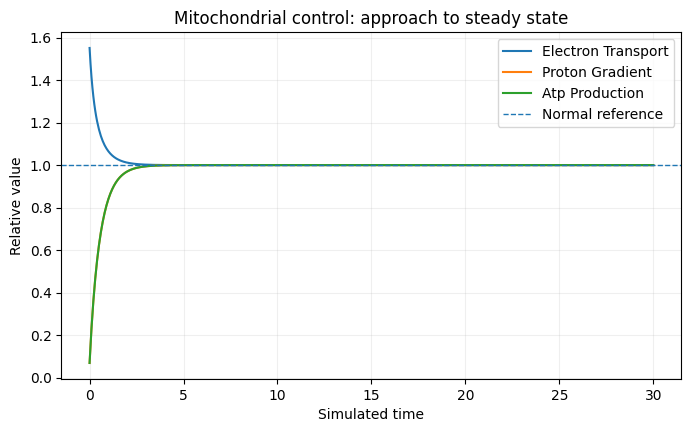

In [3]:
mito_control = simulate_mito(
    electron_transport_activity=1.0,
    proton_leak=0.10,
    atp_synthase_activity=1.0,
)

mito_control_endpoint = endpoint(mito_control)
RESULTS["Mitochondrial control"] = mito_control_endpoint

display(mito_control_endpoint.to_frame("Relative value"))

plot_time_course(
    mito_control,
    "Mitochondrial control: approach to steady state",
    ["electron_transport", "proton_gradient", "atp_production"],
)

## 3. Experiment 1 — Inhibit mitochondrial electron transport

### Before you run the experiment
Predict what should happen to:

- electron transport
- proton gradient
- ATP production
- oxygen consumption

Record your prediction in the lab protocol.

### Your task
Edit only the value assigned to `MITO_ET_ACTIVITY`.

**Suggested biological range for a strong inhibition:** approximately `0.1–0.4`.

Do not leave the value as `None`.

,Relative value
electron_transport,0.276
proton_gradient,0.276
atp_production,0.276
oxygen_consumption,0.276


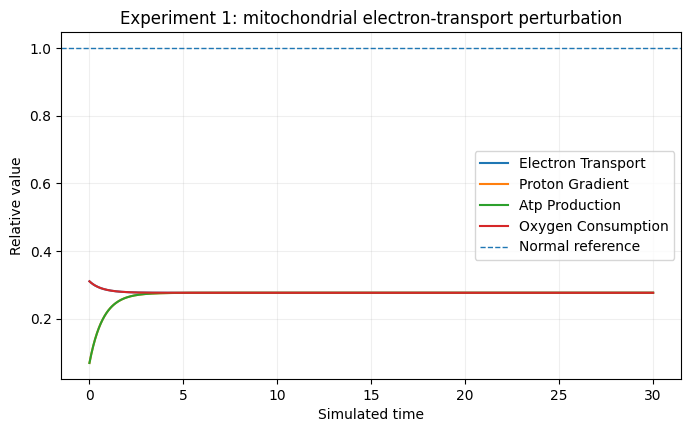

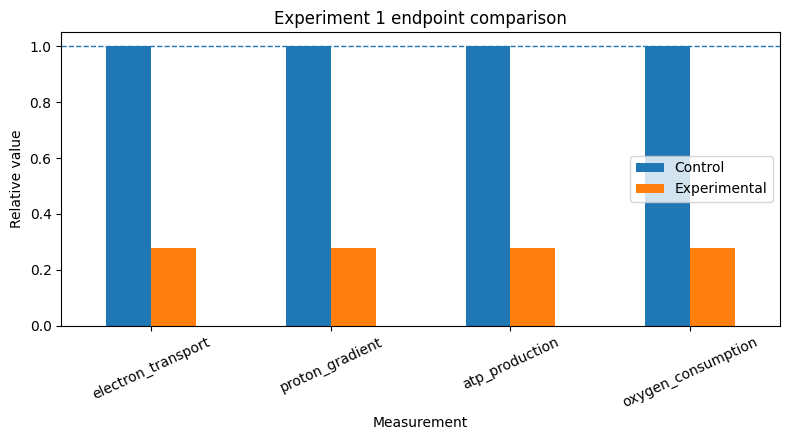

In [4]:
# TODO: Replace None with your chosen electron-transport activity.
MITO_ET_ACTIVITY = 0.20

if require_parameter_change(
    MITO_ET_ACTIVITY,
    "MITO_ET_ACTIVITY",
    control_value=1.0,
    low=0.0,
    high=1.5,
):
    mito_et_inhibited = simulate_mito(
        electron_transport_activity=MITO_ET_ACTIVITY,
        proton_leak=0.10,
        atp_synthase_activity=1.0,
    )

    mito_et_endpoint = endpoint(mito_et_inhibited)
    RESULTS["Mitochondrial ETC perturbation"] = mito_et_endpoint

    display(mito_et_endpoint.to_frame("Relative value"))

    plot_time_course(
        mito_et_inhibited,
        "Experiment 1: mitochondrial electron-transport perturbation",
        ["electron_transport", "proton_gradient", "atp_production", "oxygen_consumption"],
    )

    plot_endpoint_comparison(
        mito_control_endpoint,
        mito_et_endpoint,
        "Experiment 1 endpoint comparison",
    )

### Diagnose what happened

Use your results to answer **Question 2** in the protocol.

Your explanation must connect:

**electron transport → proton pumping → proton gradient → ATP synthase**

Also ask yourself:

> Why should oxygen consumption change when respiratory electron flow changes? When mitochondrial electron transport was inhibited, electron flow decreased. This caused fewer protons to be pumped across the inner mitochondrial membrane, resulting in a weaker proton gradient. Because ATP synthase depends on the proton gradient to produce ATP, ATP production also decreased. Oxygen consumption decreased because fewer electrons were moving through the electron transport chain. Overall, inhibiting electron transport reduced the mitochondrion's ability to produce ATP.

## 4. Experiment 2 — Inhibit mitochondrial ATP synthase

Restore electron transport and proton leak to their control values.

Now reduce ATP synthase activity.

### Before running
Predict the direction of change for:

- ATP production
- proton gradient
- electron transport
- oxygen consumption

A key concept here is **backpressure**: if protons cannot efficiently return through ATP synthase, the proton gradient can become unusually large.

### Your task
Edit `MITO_ATP_SYNTHASE`.

**Suggested range for strong inhibition:** `0.05–0.30`.

,Relative value
electron_transport,0.777
proton_gradient,1.752
atp_production,0.350
oxygen_consumption,0.777


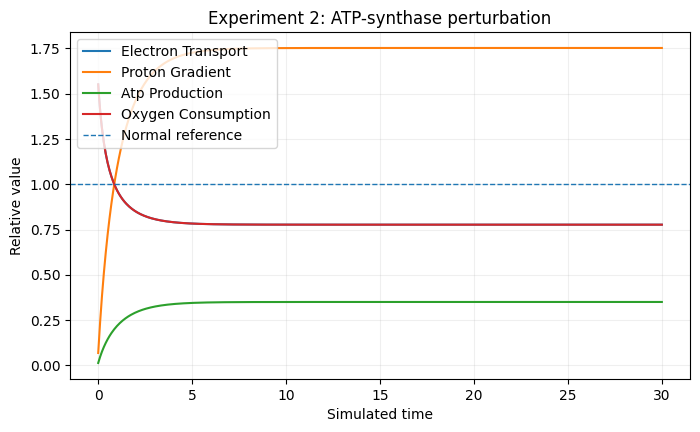

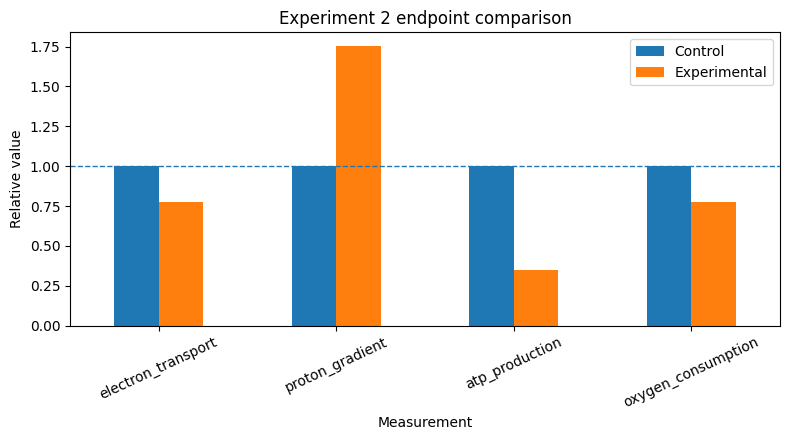

In [5]:
# TODO: Replace None with your chosen ATP-synthase activity.
MITO_ATP_SYNTHASE = 0.20

if require_parameter_change(
    MITO_ATP_SYNTHASE,
    "MITO_ATP_SYNTHASE",
    control_value=1.0,
    low=0.0,
    high=1.5,
):
    mito_atp_blocked = simulate_mito(
        electron_transport_activity=1.0,
        proton_leak=0.10,
        atp_synthase_activity=MITO_ATP_SYNTHASE,
    )

    mito_atp_endpoint = endpoint(mito_atp_blocked)
    RESULTS["Mitochondrial ATP synthase perturbation"] = mito_atp_endpoint

    display(mito_atp_endpoint.to_frame("Relative value"))

    plot_time_course(
        mito_atp_blocked,
        "Experiment 2: ATP-synthase perturbation",
        ["electron_transport", "proton_gradient", "atp_production", "oxygen_consumption"],
    )

    plot_endpoint_comparison(
        mito_control_endpoint,
        mito_atp_endpoint,
        "Experiment 2 endpoint comparison",
    )

### Interpretation prompt

Use the model output to evaluate this claim:

> “If ATP synthase is inhibited, the proton gradient should disappear.”

Is that consistent with your results? Explain **why or why not** in the protocol. When ATP synthase was inhibited, ATP production decreased, but the proton gradient increased instead of disappearing. This happened because protons could not flow back through ATP synthase as efficiently, causing them to accumulate across the inner mitochondrial membrane. The buildup created backpressure, which slowed electron transport and oxygen consumption. Therefore, inhibiting ATP synthase does not eliminate the proton gradient. Instead, it causes the gradient to become larger while ATP production decreases.

## 5. Experiment 3 — Uncouple the mitochondrion

An **uncoupler** makes the inner mitochondrial membrane more permeable to protons.

This allows H⁺ to return across the membrane without being obligatorily coupled to ATP synthase.

### Before running
Predict the direction of change for:

- electron transport
- proton gradient
- ATP production
- oxygen consumption

### Your task
Edit `MITO_PROTON_LEAK`.

The control proton leak is only `0.10`.

**Suggested uncoupled range:** approximately `0.50–1.20`.

,Relative value
electron_transport,1.289
proton_gradient,0.412
atp_production,0.412
oxygen_consumption,1.289


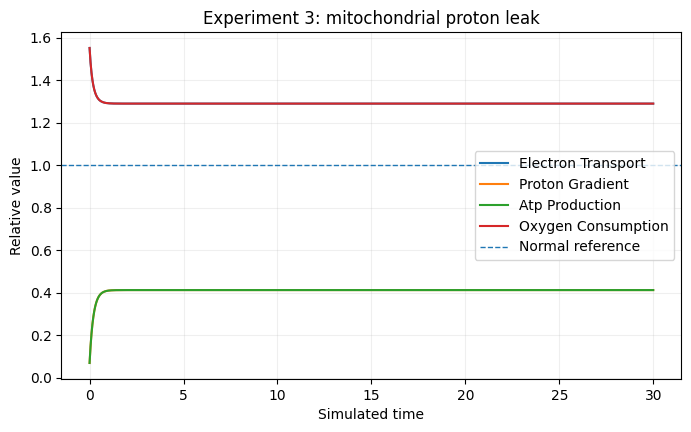

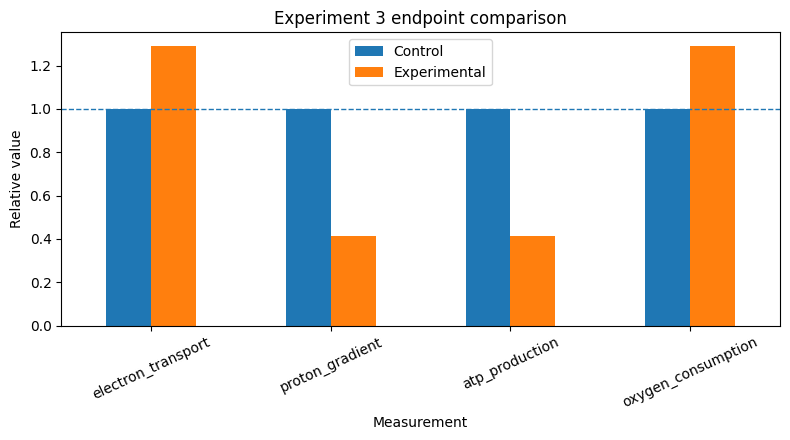

In [6]:
# TODO: Replace None with a proton-leak value greater than the control value.
MITO_PROTON_LEAK = 0.80

if require_parameter_change(
    MITO_PROTON_LEAK,
    "MITO_PROTON_LEAK",
    control_value=0.10,
    low=0.0,
    high=3.0,
):
    mito_uncoupled = simulate_mito(
        electron_transport_activity=1.0,
        proton_leak=MITO_PROTON_LEAK,
        atp_synthase_activity=1.0,
    )

    mito_uncoupled_endpoint = endpoint(mito_uncoupled)
    RESULTS["Mitochondrial proton-leak perturbation"] = mito_uncoupled_endpoint

    display(mito_uncoupled_endpoint.to_frame("Relative value"))

    plot_time_course(
        mito_uncoupled,
        "Experiment 3: mitochondrial proton leak",
        ["electron_transport", "proton_gradient", "atp_production", "oxygen_consumption"],
    )

    plot_endpoint_comparison(
        mito_control_endpoint,
        mito_uncoupled_endpoint,
        "Experiment 3 endpoint comparison",
    )

### Critical reasoning

Use the plot to explain this statement:

> **High electron transport does not necessarily mean high ATP production.**

This is the central distinction between **respiration** and **coupling efficiency**.

When the mitochondrion was uncoupled, electron transport and oxygen consumption increased, but ATP production decreased. This happened because the increased proton leak allowed protons to cross the inner mitochondrial membrane without passing through ATP synthase. As a result, the proton gradient became weaker, leaving less energy available for ATP production. Even though the electron transport chain was working faster, the energy was not being efficiently used to make ATP. This shows that high electron transport does not always mean high ATP production because ATP synthesis depends on an intact proton gradient and efficient coupling.

# Chloroplast experiments

The same general logic now moves to the thylakoid membrane.

Instead of chemical energy from NADH/FADH₂ driving respiratory electron transport, **light energy** drives photosynthetic electron transport.

The common logic remains:

**energy input → electron transport → proton gradient → ATP synthase → ATP**

## 6. Chloroplast control

,Relative value
electron_transport,1.0
proton_gradient,1.0
atp_production,1.0


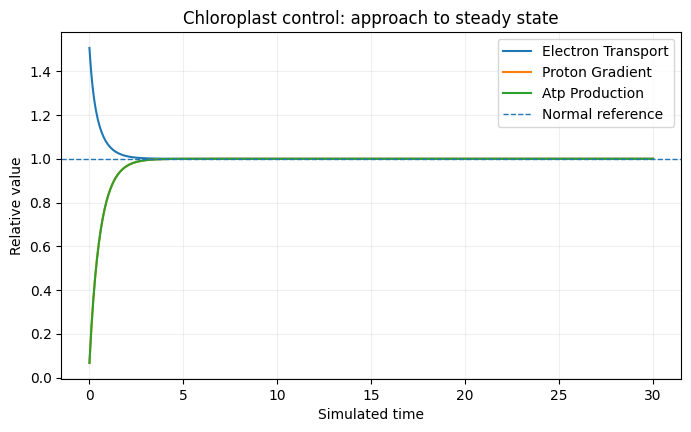

In [7]:
chloro_control = simulate_chloro(
    light_intensity=1.0,
    photosynthetic_et_activity=1.0,
    proton_leak=0.10,
    atp_synthase_activity=1.0,
)

chloro_control_endpoint = endpoint(chloro_control)
RESULTS["Chloroplast control"] = chloro_control_endpoint

display(chloro_control_endpoint.to_frame("Relative value"))

plot_time_course(
    chloro_control,
    "Chloroplast control: approach to steady state",
    ["electron_transport", "proton_gradient", "atp_production"],
)

## 7. Experiment 4 — Change light availability

### Before running
Complete this causal chain in your lab protocol:

**loss of light → ______ decreases → electron transport decreases → ______ decreases → ATP synthesis decreases**

### Your task
Edit `LIGHT_INTENSITY`.

To simulate complete darkness, use `0.0`.  
You may also test a partially illuminated condition such as `0.25` or `0.50`.

,Relative value
electron_transport,0.0
proton_gradient,0.0
atp_production,0.0


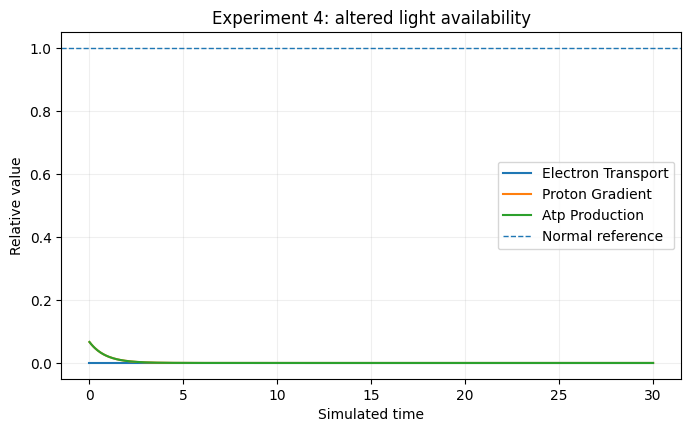

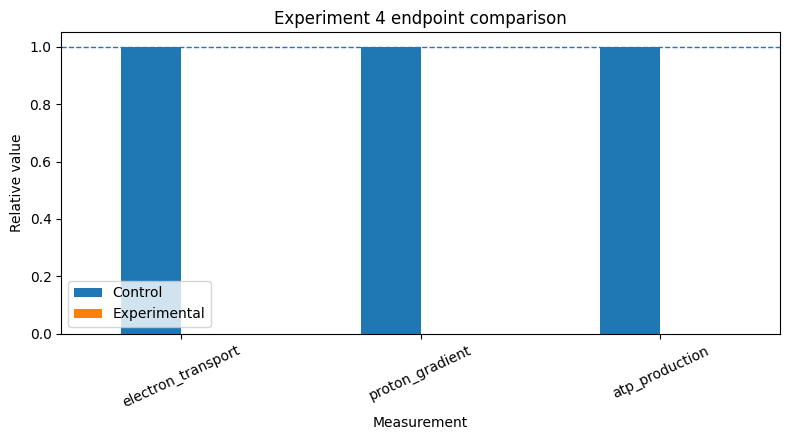

In [8]:
# TODO: Replace None with a light-intensity value.
LIGHT_INTENSITY = 0.0

if require_parameter_change(
    LIGHT_INTENSITY,
    "LIGHT_INTENSITY",
    control_value=1.0,
    low=0.0,
    high=1.5,
):
    chloro_light_test = simulate_chloro(
        light_intensity=LIGHT_INTENSITY,
        photosynthetic_et_activity=1.0,
        proton_leak=0.10,
        atp_synthase_activity=1.0,
    )

    chloro_light_endpoint = endpoint(chloro_light_test)
    RESULTS["Chloroplast light perturbation"] = chloro_light_endpoint

    display(chloro_light_endpoint.to_frame("Relative value"))

    plot_time_course(
        chloro_light_test,
        "Experiment 4: altered light availability",
        ["electron_transport", "proton_gradient", "atp_production"],
    )

    plot_endpoint_comparison(
        chloro_control_endpoint,
        chloro_light_endpoint,
        "Experiment 4 endpoint comparison",
    )

## 8. Experiment 5 — Inhibit photosynthetic electron transport

Restore light to the control value.

This time, light is available but the machinery that uses that energy to move electrons is impaired.

### Your task
Edit `PHOTO_ET_ACTIVITY`.

**Suggested range for strong inhibition:** `0.10–0.40`.

Before running the cell, predict whether abundant light can maintain normal ATP production when photosynthetic electron transport is strongly inhibited.

,Relative value
electron_transport,0.271
proton_gradient,0.271
atp_production,0.271


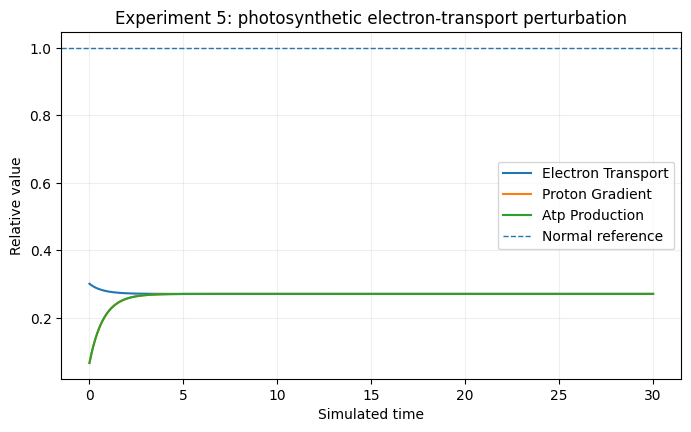

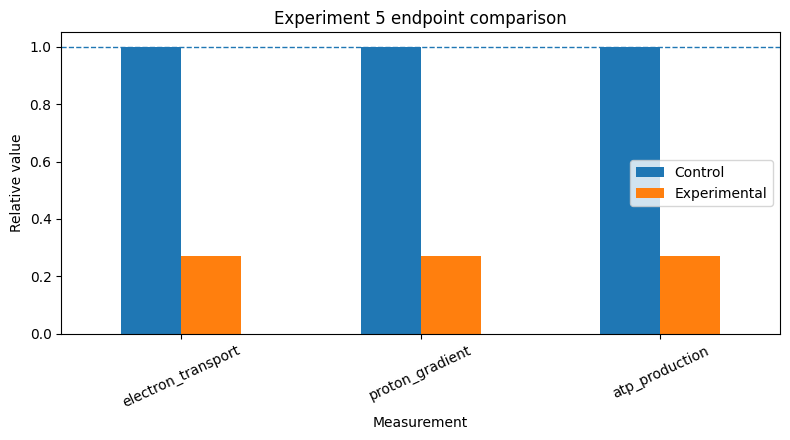

In [9]:
# TODO: Replace None with your chosen photosynthetic electron-transport activity.
PHOTO_ET_ACTIVITY = 0.20

if require_parameter_change(
    PHOTO_ET_ACTIVITY,
    "PHOTO_ET_ACTIVITY",
    control_value=1.0,
    low=0.0,
    high=1.5,
):
    chloro_et_test = simulate_chloro(
        light_intensity=1.0,
        photosynthetic_et_activity=PHOTO_ET_ACTIVITY,
        proton_leak=0.10,
        atp_synthase_activity=1.0,
    )

    chloro_et_endpoint = endpoint(chloro_et_test)
    RESULTS["Chloroplast electron-transport perturbation"] = chloro_et_endpoint

    display(chloro_et_endpoint.to_frame("Relative value"))

    plot_time_course(
        chloro_et_test,
        "Experiment 5: photosynthetic electron-transport perturbation",
        ["electron_transport", "proton_gradient", "atp_production"],
    )

    plot_endpoint_comparison(
        chloro_control_endpoint,
        chloro_et_endpoint,
        "Experiment 5 endpoint comparison",
    )

# 9. Diagnostic challenge — What has been perturbed?

You are now given **three unknown mitochondrial conditions**.

Possible diagnoses are:

1. **Electron-transport inhibition**
2. **ATP-synthase inhibition**
3. **Uncoupling / greatly increased proton permeability**

For each mystery:

- identify the most likely perturbation,
- cite at least **two measurements** that support your diagnosis,
- explain the mechanistic reason for the pattern.

Do not diagnose from ATP production alone.

,electron_transport,proton_gradient,atp_production,oxygen_consumption
Mystery A,0.29,0.29,0.29,0.29
Mystery B,0.71,2.04,0.20,0.71
Mystery C,1.45,0.18,0.12,1.45


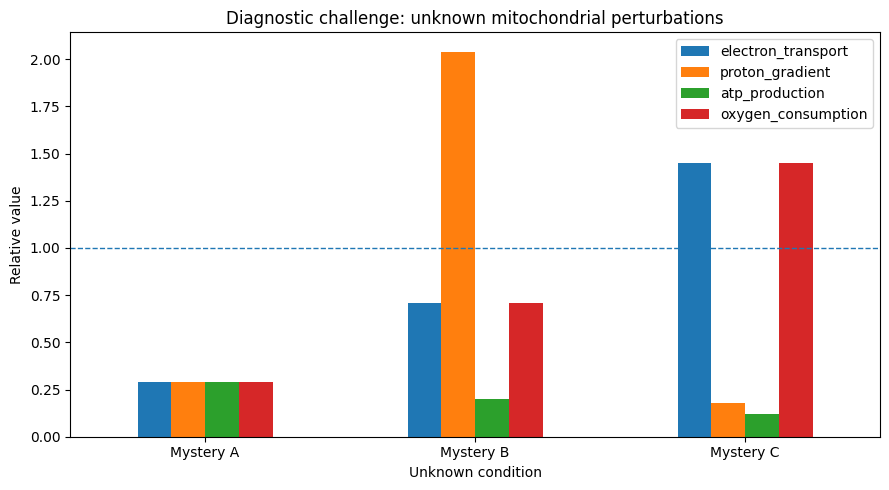

In [10]:
# These conditions are intentionally displayed only as phenotypes.
# Diagnose them from the pattern of measurements.

mystery_data = pd.DataFrame(
    {
        "Mystery A": {
            "electron_transport": 0.29,
            "proton_gradient": 0.29,
            "atp_production": 0.29,
            "oxygen_consumption": 0.29,
        },
        "Mystery B": {
            "electron_transport": 0.71,
            "proton_gradient": 2.04,
            "atp_production": 0.20,
            "oxygen_consumption": 0.71,
        },
        "Mystery C": {
            "electron_transport": 1.45,
            "proton_gradient": 0.18,
            "atp_production": 0.12,
            "oxygen_consumption": 1.45,
        },
    }
).T

display(mystery_data)

ax = mystery_data.plot(kind="bar", figsize=(9, 5))
ax.set_title("Diagnostic challenge: unknown mitochondrial perturbations")
ax.set_xlabel("Unknown condition")
ax.set_ylabel("Relative value")
ax.axhline(1.0, linestyle="--", linewidth=1)
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

### Diagnostic questions

Record your diagnoses in the lab protocol.

For each mystery, ask:

- Is electron flow itself low?
- Is the proton gradient unusually high?
- Is the gradient collapsing while electron transport stays high?
- Is ATP synthesis moving in the same direction as electron transport, or has coupling been lost?

### Especially important
A condition with:

**high electron transport + low proton gradient + low ATP**

is mechanistically very different from:

**low electron transport + low proton gradient + low ATP**.

# 10. Design your own experiment

Choose **one organelle** and change **exactly one major variable**.

This is your opportunity to test a biological hypothesis rather than reproduce a prescribed condition.

Examples:

- moderate mitochondrial uncoupling instead of severe uncoupling,
- increased mitochondrial electron-transport capacity,
- partial darkness,
- increased chloroplast proton leak,
- partial chloroplast ATP-synthase inhibition.

### First write your hypothesis in the protocol

Use:

> **If ______ is changed, then ______ will occur because ______.**

Then edit the appropriate code cell below.

In [11]:
# ------------------------------------------------------------
# STUDENT-DESIGNED EXPERIMENT
# ------------------------------------------------------------

# TODO 1:
# Choose exactly one of these strings:
# "mitochondrion" or "chloroplast"
ORGANELLE = "mitochondrion"

# TODO 2:
# Leave all control values unchanged EXCEPT ONE major parameter.

# Mitochondrial parameters
DESIGN_MITO_ET = 1.50
DESIGN_MITO_LEAK = 0.10
DESIGN_MITO_ATP_SYNTHASE = 1.0

# Chloroplast parameters
DESIGN_LIGHT = 1.0
DESIGN_PHOTO_ET = 1.0
DESIGN_CHLORO_LEAK = 0.10
DESIGN_CHLORO_ATP_SYNTHASE = 1.0

def count_changes(values, controls):
    return sum(not np.isclose(float(v), float(c)) for v, c in zip(values, controls))

if ORGANELLE is None:
    print("STOP: Choose an organelle by replacing None with 'mitochondrion' or 'chloroplast'.")

elif ORGANELLE == "mitochondrion":
    design_values = [DESIGN_MITO_ET, DESIGN_MITO_LEAK, DESIGN_MITO_ATP_SYNTHASE]
    control_values = [1.0, 0.10, 1.0]

    if count_changes(design_values, control_values) != 1:
        print("STOP: For the designed experiment, change exactly ONE mitochondrial parameter.")
    else:
        designed_trace = simulate_mito(
            electron_transport_activity=DESIGN_MITO_ET,
            proton_leak=DESIGN_MITO_LEAK,
            atp_synthase_activity=DESIGN_MITO_ATP_SYNTHASE,
        )
        designed_endpoint = endpoint(designed_trace)
        RESULTS["Student-designed experiment"] = designed_endpoint
        display(designed_endpoint.to_frame("Relative value"))

elif ORGANELLE == "chloroplast":
    design_values = [DESIGN_LIGHT, DESIGN_PHOTO_ET, DESIGN_CHLORO_LEAK, DESIGN_CHLORO_ATP_SYNTHASE]
    control_values = [1.0, 1.0, 0.10, 1.0]

    if count_changes(design_values, control_values) != 1:
        print("STOP: For the designed experiment, change exactly ONE chloroplast parameter.")
    else:
        designed_trace = simulate_chloro(
            light_intensity=DESIGN_LIGHT,
            photosynthetic_et_activity=DESIGN_PHOTO_ET,
            proton_leak=DESIGN_CHLORO_LEAK,
            atp_synthase_activity=DESIGN_CHLORO_ATP_SYNTHASE,
        )
        designed_endpoint = endpoint(designed_trace)
        RESULTS["Student-designed experiment"] = designed_endpoint
        display(designed_endpoint.to_frame("Relative value"))

else:
    raise ValueError("ORGANELLE must be either 'mitochondrion' or 'chloroplast'.")

,Relative value
electron_transport,1.332
proton_gradient,1.332
atp_production,1.332
oxygen_consumption,1.332


## 11. Generate your own plot

This is the one place where **you choose what to visualize**.

Choose at least **two** measurements that best test your hypothesis.

### Valid mitochondrial metric names
- `"electron_transport"`
- `"proton_gradient"`
- `"atp_production"`
- `"oxygen_consumption"`

### Valid chloroplast metric names
- `"electron_transport"`
- `"proton_gradient"`
- `"atp_production"`

Python lists use square brackets, for example:

`["proton_gradient", "atp_production"]`

Do **not** simply copy that example automatically. Choose measurements that actually address your hypothesis.

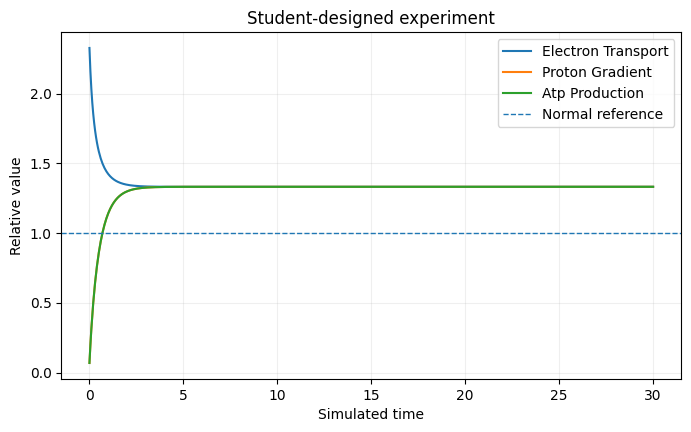

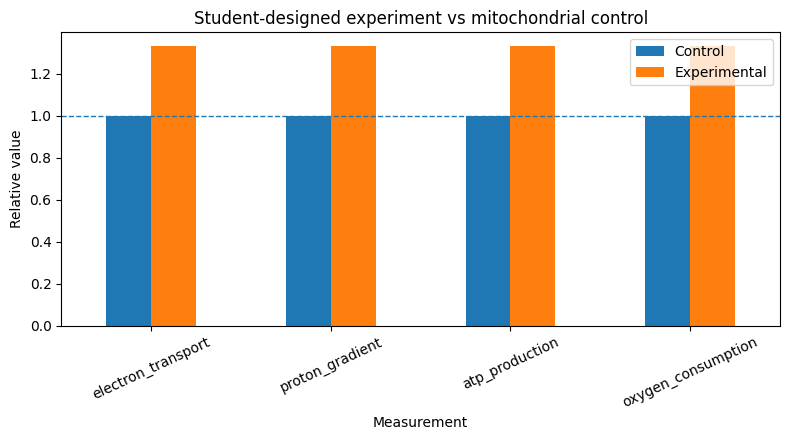

In [14]:
# TODO: Replace None with a Python list containing at least two metrics.
METRICS_TO_PLOT = [
    "electron_transport",
    "proton_gradient",
    "atp_production"
]

if "designed_trace" not in globals():
    print("STOP: Complete and run your student-designed experiment first.")

else:
    valid = [c for c in designed_trace.columns if c != "time"]

    if require_plot_metrics(METRICS_TO_PLOT, valid):
        plot_time_course(
            designed_trace,
            "Student-designed experiment",
            METRICS_TO_PLOT,
        )

        if ORGANELLE == "mitochondrion":
            plot_endpoint_comparison(
                mito_control_endpoint,
                designed_endpoint,
                "Student-designed experiment vs mitochondrial control",
            )
        else:
            plot_endpoint_comparison(
                chloro_control_endpoint,
                designed_endpoint,
                "Student-designed experiment vs chloroplast control",
            )

# 12. Results dashboard

Run the cell below near the end of lab.

It summarizes **only experiments you actually completed successfully**.

If an experimental section is missing, go back to that section, edit the required parameter, and rerun it.

In [15]:
if not RESULTS:
    print("No completed experiments are currently stored.")
else:
    results_table = pd.DataFrame(RESULTS).T
    display(results_table)

    print(f"\nCompleted conditions stored: {len(results_table)}")

    expected_core = [
        "Mitochondrial control",
        "Mitochondrial ETC perturbation",
        "Mitochondrial ATP synthase perturbation",
        "Mitochondrial proton-leak perturbation",
        "Chloroplast control",
        "Chloroplast light perturbation",
        "Chloroplast electron-transport perturbation",
        "Student-designed experiment",
    ]

    missing = [name for name in expected_core if name not in RESULTS]

    if missing:
        print("\nStill missing:")
        for item in missing:
            print(" -", item)
    else:
        print("\nAll required computational conditions have been completed.")

,atp_production,electron_transport,oxygen_consumption,proton_gradient
Mitochondrial control,1.000,1.000,1.000,1.000
Mitochondrial ETC perturbation,0.276,0.276,0.276,0.276
Mitochondrial ATP synthase perturbation,0.350,0.777,0.777,1.752
Mitochondrial proton-leak perturbation,0.412,1.289,1.289,0.412
Chloroplast control,1.000,1.000,NaN,1.000
Chloroplast light perturbation,0.000,0.000,NaN,0.000
Chloroplast electron-transport perturbation,0.271,0.271,NaN,0.271
Student-designed experiment,1.332,1.332,1.332,1.332



Completed conditions stored: 8

All required computational conditions have been completed.


# 13. Final biological synthesis

Before leaving lab, you should be able to explain the following without referring to code:

### Mitochondria
Why can an uncoupled mitochondrion consume oxygen rapidly while producing relatively little ATP?
An uncoupled mitochondrion consumes oxygen rapidly because protons leak across the inner mitochondrial membrane instead of passing through ATP synthase. This weakens the proton gradient and reduces ATP production. Electron transport increases because there is less backpressure, causing oxygen consumption to increase even though less ATP is produced.

### Chloroplasts
Why is light insufficient for ATP production if photosynthetic electron transport is blocked?
Light alone is not enough to produce ATP because photosynthetic electron transport is needed to pump protons across the thylakoid membrane. When electron transport is blocked, the proton gradient cannot be maintained. Without this gradient, ATP synthase cannot efficiently produce ATP, even when light is available.

### Shared mechanism
How can two organelles with very different energy sources use the same general strategy for ATP synthesis?
Mitochondria and chloroplasts both use a process called chemiosmosis to produce ATP. Mitochondria use chemical energy from NADH and FADH₂, while chloroplasts use light energy. Both organelles use electron transport to pump protons across a membrane, creating an electrochemical gradient. ATP synthase then uses the energy stored in this gradient to produce ATP from ADP and inorganic phosphate.

Your final explanation should connect:

**energy source → electron transport → proton pumping → electrochemical gradient → ATP synthase → ATP**

---

## Troubleshooting

### “STOP: Replace None...”
This is intentional. Edit the requested parameter in that cell.

### I changed a parameter but nothing happened
Make sure you reran the **same code cell** after editing it.

### `NameError`
Run the **Setup** cell near the top of the notebook, then rerun the experiment.

### My graph looks strange
Check whether you accidentally entered a value far outside the suggested range.

### I accidentally changed the model code
Use **Edit → Undo**, or reopen a clean copy of the notebook.

### Colab disconnected
Reconnect the runtime and rerun the Setup and control cells. Your typed code usually remains in the notebook, but calculated variables stored in memory may be lost.

---

## Submission reminder

Follow the Canvas instructions in the written BIOL 360 lab protocol.

Unless your instructor specifically asks for it, the notebook itself is the **experimental tool**; your biological predictions, diagnoses, and explanations belong in the lab protocol submission.